In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import os
from matplotlib.ticker import MaxNLocator

In [2]:
def plot_comprehensive_dotplot(df_long, save_path='ablation_dotplot_final.png', xlim_settings=None, alpha_val=0.7, wspace_val=0.3):
    """
    绘制点图。逻辑与你提供的代码基本一致。
    """
    # 确保没有 Macro Average 混入
    df_plot = df_long[df_long['Class'] != 'Macro Average'].copy()
    
    # 设置绘图风格
    sns.set_theme(style="whitegrid", font_scale=1.4)
    
    # --- 样式定义 ---
    palette = {
        'Baseline': '#95a5a6',  # 灰色
        'WID':      '#f1c40f',  # 黄色
        'EDL':      '#3498db',  # 蓝色
        'WID+EDL':  '#e74c3c'   # 红色
    }
    
    markers = {
        'Baseline': 'X',
        'WID':      '^',
        'EDL':      's',
        'WID+EDL':  'o'
    }
    
    # 排序：确保按照指定的顺序排列类别
    target_order = ['Consolidation', 'Edema', 'Cardiomegaly', 'Pleural Effusion', 'Pneumonia']
    # 过滤掉数据中不存在的类别防止报错
    existing_classes = [cls for cls in target_order if cls in df_plot['Class'].unique()]
    df_plot['Class'] = pd.Categorical(df_plot['Class'], categories=existing_classes, ordered=True)

    # === 绘图 ===
    g = sns.relplot(
        data=df_plot, 
        x="Score", 
        y="Class", 
        hue="Method", 
        style="Method",       
        col="Metric",
        kind="scatter",       
        palette=palette,
        markers=markers,    
        height=max(4, len(existing_classes) * 0.8),  
        aspect=0.7,           
        s=200,              
        edgecolor='white',  
        linewidth=1.0,
        alpha=alpha_val,     
        facet_kws={'sharex': False} 
    )
    
    # === 美化细节 ===
    axes_dict = g.axes_dict
    
    for metric_name, ax in axes_dict.items():
        ax.grid(True, axis='x', linestyle='--', alpha=0.6)
        
        # 设置 X 轴范围
        if xlim_settings and metric_name in xlim_settings:
            ax.set_xlim(xlim_settings[metric_name])
        else:
            current_min = df_plot[df_plot['Metric']==metric_name]['Score'].min()
            ax.set_xlim(max(0, current_min - 0.05), 1.02)
            
        ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
        
        for label in ax.get_xticklabels():
            label.set_rotation(45)
            label.set_ha('right')

    g.set_titles("{col_name}", fontweight='bold', fontsize=18) 
    g.set_axis_labels("Score", "", fontsize=16) 
    
    plt.subplots_adjust(top=0.85, bottom=0.20, wspace=wspace_val) 

    sns.move_legend(
        g, "lower center",
        bbox_to_anchor=(0.5, -0.15),
        ncol=4, 
        title=None, 
        frameon=False, 
        fontsize=14
    )
    
    if save_path:
        os.makedirs(os.path.dirname(save_path) if os.path.dirname(save_path) else '.', exist_ok=True)
        plt.savefig(save_path, dpi=300, bbox_inches='tight') 
        print(f"Plot saved to: {save_path}")
    
    plt.show()

In [3]:
def collect_data_from_multiple_files(dataset_name, subset_name, methods_config, target_classes):
    df_list = []
    # 我们只读取这些列，自动忽略 CI_Lower, CI_Upper 等列
    metrics_to_plot = ['AUC', 'Accuracy', 'Sensitivity', 'Specificity', 'F1_Score']
    
    for method_name, config in methods_config.items():
        loss_type = config['loss']
        imgdec_val = config['imgdec']
        
        for class_name in target_classes:
            # 动态构建路径
            folder_name = (
                f"0203_{class_name.replace(" ", "_")}_wd0_0001_gc1_0_vw1_0_{loss_type}_"
                f"lr_0.0005_kllmd_0.1_imgdec_{imgdec_val}"
            )
            # [修改点] 文件名为 final_metrics.csv
            file_path = f'../result/{dataset_name}/{folder_name}/{subset_name}_evaluation_results/final_metrics.csv'
            
            if not os.path.exists(file_path):
                print(f"[Warning] Not found: {file_path}")
                continue
            
            try:
                df = pd.read_csv(file_path)
                
                # =======================================================
                # [核心筛选逻辑]
                # 1. Branch == 'Main'
                # 2. Class == 当前循环的 class_name
                # =======================================================
                # 注意：有些CSV里的Branch列可能有空格，用 strip() 保险
                if 'Branch' in df.columns:
                    df['Branch'] = df['Branch'].astype(str).str.strip()
                
                condition = (df['Branch'] == 'Main') & (df['Class'] == class_name)
                df_target_row = df[condition].copy()
                
                if df_target_row.empty:
                    print(f"[Skip] No 'Main' branch data for class '{class_name}' in {file_path}")
                    continue
                
                # 理论上应该只有一行，如果有重复，默认取第一行
                if len(df_target_row) > 1:
                    df_target_row = df_target_row.iloc[[0]]

                # 只保留 Metric 列 (自动丢弃 CI 列)
                # 添加 Class 列用于后续合并 (虽然行里已有，但为了保险起见显式保留)
                cols_to_keep = ['Class'] + metrics_to_plot
                existing_cols = [c for c in cols_to_keep if c in df_target_row.columns]
                
                df_subset = df_target_row[existing_cols].copy()
                df_subset['Method'] = method_name
                
                # Melt 转换
                df_melted = df_subset.melt(
                    id_vars=['Class', 'Method'],
                    value_vars=[c for c in metrics_to_plot if c in df_subset.columns],
                    var_name='Metric',
                    value_name='Score'
                )
                df_list.append(df_melted)
                
            except Exception as e:
                print(f"[Error] Processing {file_path}: {e}")

    if not df_list:
        raise ValueError("No valid data loaded.")
        
    return pd.concat(df_list, ignore_index=True)

Starting data collection...
Data loaded successfully. Total rows: 80
           Class    Method       Metric     Score
0  Consolidation  Baseline          AUC  0.933719
1  Consolidation  Baseline     Accuracy  0.835443
2  Consolidation  Baseline  Sensitivity  0.783784
3  Consolidation  Baseline  Specificity  0.880952
4  Consolidation  Baseline     F1_Score  0.816901
Generating plot...
Plot saved to: ./figures/MIMIC/0203/ablation_comparison_separate_files.png


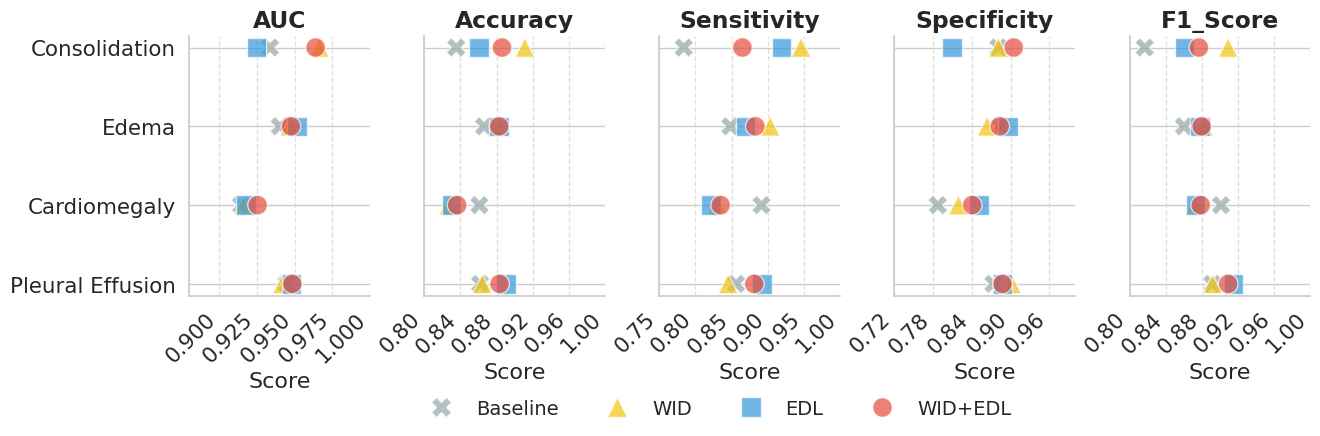

In [4]:
dataset_name = 'MIMIC'
subset_name = 'val'

# 定义需要合并的5个类别
target_classes = ['Consolidation', 'Edema', 'Cardiomegaly', 'Pleural Effusion']

# 定义不同方法的路径参数配置
# 根据你提供的路径规律提取出来的差异点
methods_config = {
    'Baseline': {'loss': 'lm_bce',    'imgdec': 0},
    'WID':      {'loss': 'lm_bce',    'imgdec': 1},
    'EDL':      {'loss': 'lm_bcevar', 'imgdec': 0},
    'WID+EDL':  {'loss': 'lm_bcevar', 'imgdec': 1}
}

# 坐标轴范围设置
my_xlims = {
    'AUC': (0.88, 1.0),
    'Accuracy': (0.80, 1.0),
    'Sensitivity': (0.75, 1.0),  
    'Specificity': (0.72, 1.0),   
    'F1_Score': (0.8, 1.0)
}

try:
    print("Starting data collection...")
    
    # 1. 收集并合并数据
    final_df = collect_data_from_multiple_files(
        dataset_name, 
        subset_name, 
        methods_config, 
        target_classes
    )
    
    print(f"Data loaded successfully. Total rows: {len(final_df)}")
    print(final_df.head())
    
    # 2. 绘图
    print("Generating plot...")
    save_path = f'./figures/{dataset_name}/0203/ablation_comparison_separate_files.png'
    
    plot_comprehensive_dotplot(
        final_df, 
        save_path=save_path, 
        xlim_settings=my_xlims
    )
    
except Exception as e:
    import traceback
    traceback.print_exc()
    print(f"An error occurred: {e}")